# What's new in PyHealth 2.1 (1/3): splits you can trust, runs you can repeat

PyHealth 2.1 closes two quiet problems that make clinical ML results look better, or less stable, than they are:

- **Preprocessing that has seen the test patients.** Splitting *after* building samples fits code vocabularies on everyone, test patients included.
- **Runs you can't repeat.** The same script gave different numbers from run to run.

**Time:** about 10 minutes on a free Colab CPU runtime. Data is synthetic, so no credentials are needed.

**How to run:** Runtime > Run all, or Shift+Enter cell by cell. The text above each code cell says what it does; the text below says how to read its output.

## Visual guide

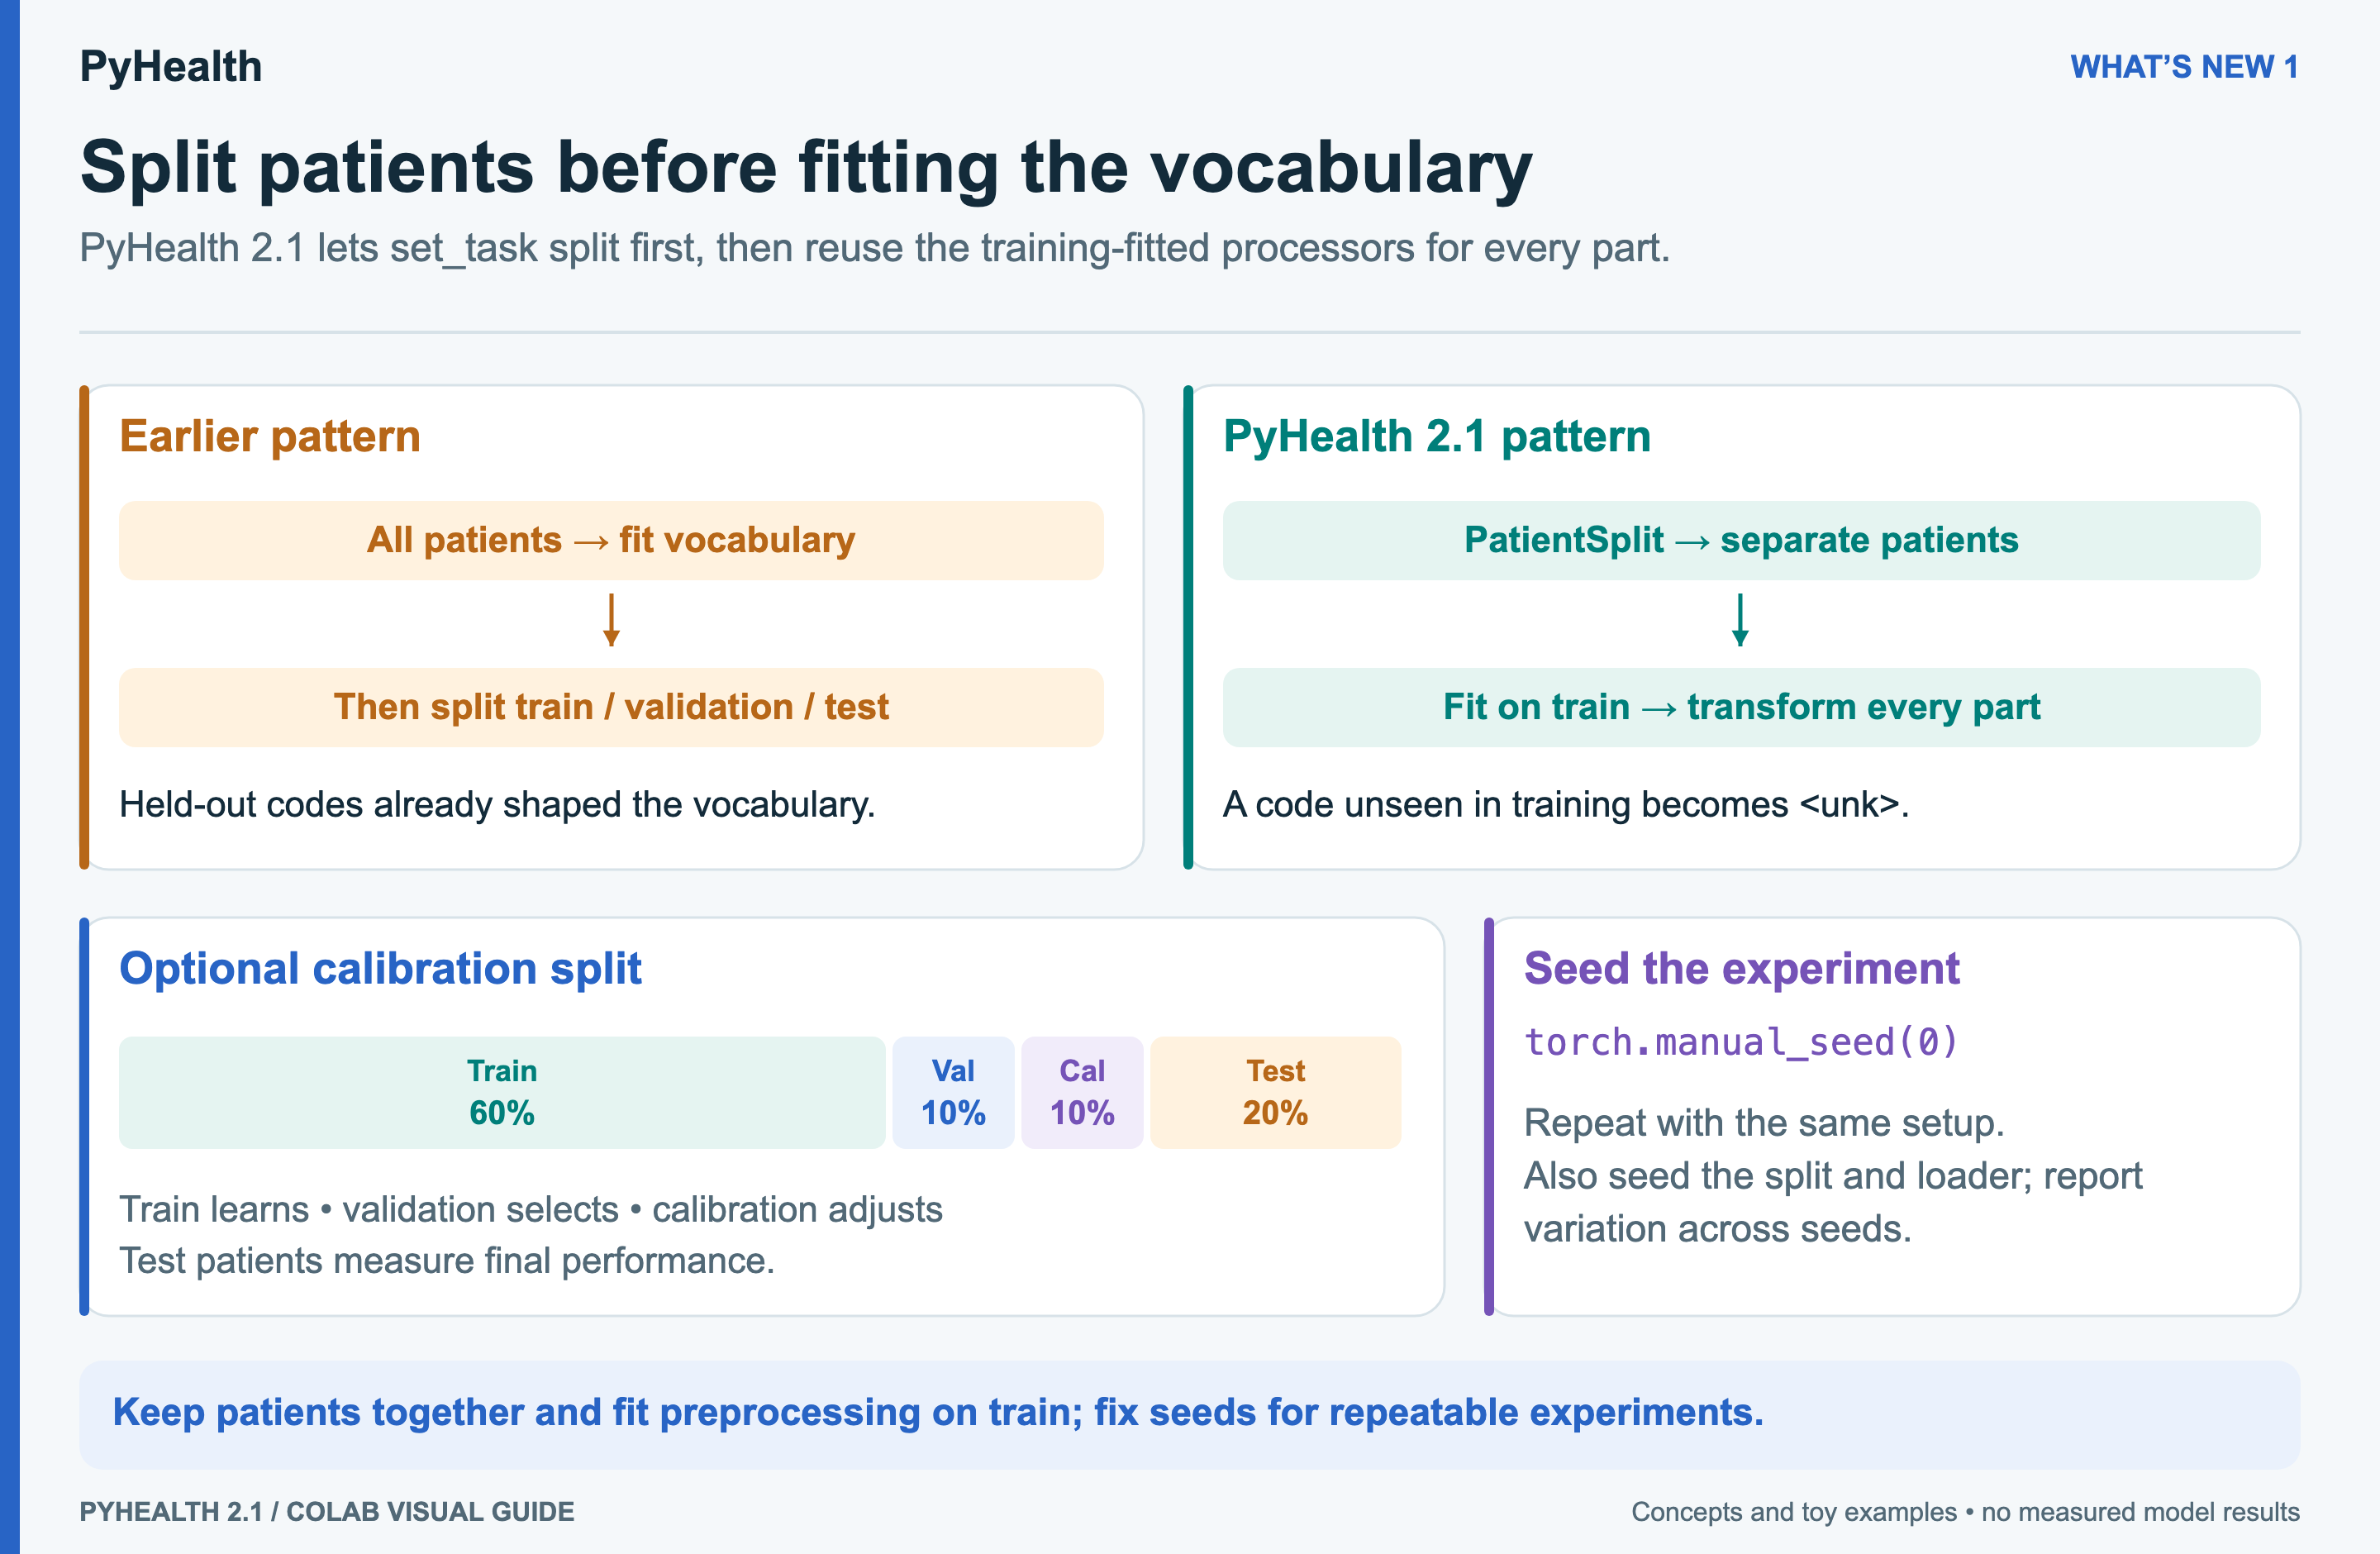

Splitting before fitting processors prevents held-out patients from shaping the vocabulary. A fourth split supports calibration; explicit seeds make comparisons repeatable in the same setup.


## Setup

This installs **PyHealth 2.1.0** from PyPI. On Colab choose **Runtime > Run all**. If the install has to upgrade a package Colab already loaded, the runtime restarts once ("Your session crashed"); choose **Runtime > Run all** again. Output is kept short: PyHealth's step-by-step build logs are hidden.

In [1]:
# Installs PyHealth 2.1.0 from PyPI (about 1-2 minutes the first time).
# If the install upgrades a package Python has already loaded (Colab
# preloads a few, such as numpy), the runtime restarts once: Colab then
# shows "Your session crashed". That is expected. Choose Runtime > Run all
# again and everything runs through; this cell will then skip the install.
import importlib.metadata as md
import os
import subprocess
import sys

PYHEALTH_VERSION = "2.1.0"
EXTRAS = "xgboost"


def installed(dist):
    try:
        return md.version(dist)
    except md.PackageNotFoundError:
        return None


if installed("pyhealth") != PYHEALTH_VERSION:
    # Remember which installed packages are already imported, and at what version.
    owners = md.packages_distributions()
    loaded = {}
    for module in list(sys.modules):
        for dist in owners.get(module, []):
            loaded[dist] = installed(dist)

    print(f"Installing PyHealth {PYHEALTH_VERSION}...")
    result = subprocess.run(
        # ipywidgets draws the progress bars while a dataset is built; Colab
        # already has it, other Jupyter setups may not.
        [sys.executable, "-m", "pip", "install", "-q",
         f"pyhealth[{EXTRAS}]=={PYHEALTH_VERSION}", "ipywidgets"],
        capture_output=True, text=True,
    )
    if result.returncode != 0:
        print(result.stdout[-5000:], result.stderr[-5000:])
        raise RuntimeError("Installing PyHealth failed; see the log above.")

    changed = sorted(d for d, v in loaded.items() if installed(d) != v)
    if changed:
        print("Upgraded packages that were already loaded:", ", ".join(changed))
        print("Restarting the runtime. When Colab says the session crashed, "
              "choose Runtime > Run all again.")
        os.kill(os.getpid(), 9)  # Colab restarts the runtime automatically

import logging
import warnings

import pyhealth
import torch

# Keep the output readable: hide the step-by-step logs of dataset and task
# building (progress bars still show), keep the per-epoch training scores,
# and skip the printout of every model's layers. To see everything, run
# logging.getLogger("pyhealth").setLevel(logging.INFO)
logging.getLogger("pyhealth").setLevel(logging.WARNING)
logging.getLogger("pyhealth.trainer").setLevel(logging.INFO)
logging.getLogger("pyhealth.trainer").addFilter(
    lambda record: not isinstance(record.msg, torch.nn.Module))
# PyHealth 2.1.0 pins litdata, which then suggests upgrading on every run.
warnings.filterwarnings("ignore", message="A newer version of litdata")
print(f"PyHealth {installed('pyhealth')} is ready | "
      f"device: {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")

Installing PyHealth 2.1.0...
PyHealth 2.1.0 is ready | device: CPU


## Load the data

The public synthetic copy of MIMIC-III and the mortality task from the Quickstart: from the codes of one admission, predict death in hospital during the next admission. The first run downloads and caches the tables (a couple of minutes).

In [2]:
from pyhealth.datasets import MIMIC3Dataset
from pyhealth.tasks import MortalityPredictionMIMIC3

dataset = MIMIC3Dataset(
    root="https://storage.googleapis.com/pyhealth/Synthetic_MIMIC-III",
    tables=["diagnoses_icd", "procedures_icd", "prescriptions"],
    cache_dir="pyhealth_cache",
)
task = MortalityPredictionMIMIC3()

/usr/local/lib/python3.13/dist-packages/pyhealth/datasets/mimic3.py:59: UserWarning: Events from prescriptions table only have date timestamp (no specific time). This may affect temporal ordering of events.
  warnings.warn(


## 1. The old way: split after building samples

In 2.0 the usual pattern was `samples = dataset.set_task(task)` and then `split_by_patient(samples, ...)`. Patients never appear in two parts, which is good. But the processors were fitted on **all** samples first, so the code vocabulary includes codes that only test patients have. A deployed model would never have seen those codes.

In [3]:
from pyhealth.datasets import split_by_patient

all_samples = dataset.set_task(task)
old_train, old_val, old_test = split_by_patient(all_samples, [0.7, 0.1, 0.2], seed=42)
old_vocab = len(all_samples.input_processors["conditions"].code_vocab)
print(f"diagnosis vocabulary, fitted on ALL patients: {old_vocab} codes")

  0%|          | 0/49993 [00:00<?, ?it/s]

Rank 0 inferred the following `['bytes']` data format.


  0%|          | 0/2194 [00:00<?, ?it/s]

Rank 0 inferred the following `['no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:1', 'bytes']` data format.


100%|██████████| 2194/2194 [00:00<00:00, 4989.53it/s]

diagnosis vocabulary, fitted on ALL patients: 2529 codes


## 2. New in 2.1: split first, fit on training patients only

Pass `split=PatientSplit(...)` to `set_task`. PyHealth splits by patient first, fits every processor on the training patients only, and returns one dataset per part. Codes seen only in validation or test map to `<unk>`, exactly as unseen codes would in practice.

In [4]:
from pyhealth.datasets import PatientSplit

train_ds, val_ds, test_ds = dataset.set_task(task, split=PatientSplit((0.7, 0.1, 0.2), seed=42))
new_vocab = len(train_ds.input_processors["conditions"].code_vocab)
unk = train_ds.input_processors["conditions"].code_vocab["<unk>"]
test_codes = [int(c) for i in range(len(test_ds)) for c in test_ds[i]["conditions"]]

print(f"diagnosis vocabulary, fitted on TRAINING patients: {new_vocab} codes "
      f"({old_vocab - new_vocab} fewer)")
print(f"{sum(c == unk for c in test_codes) / len(test_codes):.1%} of test diagnosis codes are unseen in training")

  0%|          | 0/2194 [00:00<?, ?it/s]

Rank 0 inferred the following `['no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:1', 'bytes']` data format.


100%|██████████| 2194/2194 [00:00<00:00, 5368.45it/s]


diagnosis vocabulary, fitted on TRAINING patients: 2198 codes (331 fewer)
5.1% of test diagnosis codes are unseen in training


**Reading it:** the difference between the two vocabularies is codes the old pipeline let the model "know" from test patients. The unseen share is what a real deployment faces, and now your evaluation faces it too. For processors that learn statistics (such as normalisation), the same rule applies, and PyHealth 2.1 warns when one is fitted on all samples.

## 3. More than three parts

`PatientSplit` takes two or more ratios. A common fourth part is a **calibration set**, used to recalibrate probabilities or fit a conformal predictor without touching the test set.

In [5]:
train4, val4, calib4, test4 = dataset.set_task(task, split=PatientSplit((0.6, 0.1, 0.1, 0.2), seed=42))
print(f"train {len(train4)}  val {len(val4)}  calibration {len(calib4)}  test {len(test4)}")

  0%|          | 0/2194 [00:00<?, ?it/s]

Rank 0 inferred the following `['no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:1', 'bytes']` data format.


100%|██████████| 2194/2194 [00:00<00:00, 5277.47it/s]


train 1322  val 217  calibration 220  test 435


## 4. Runs you can repeat

In 2.1, `torch.manual_seed` alone makes a run repeatable: each data loader gets its own seeded, per-epoch shuffle, and building datasets or explaining models no longer changes the global random state.

The function below trains a small RNN for two epochs. Same seed in, same score out; a different seed gives a different, equally valid run.

In [6]:
import torch
from pyhealth.datasets import get_dataloader
from pyhealth.models import RNN
from pyhealth.trainer import Trainer


def run(seed):
    torch.manual_seed(seed)
    trainer = Trainer(model=RNN(dataset=train_ds), metrics=["roc_auc"], enable_logging=False)
    trainer.train(
        train_dataloader=get_dataloader(train_ds, batch_size=64, shuffle=True),
        val_dataloader=get_dataloader(val_ds, batch_size=256),
        epochs=2,
    )
    return trainer.evaluate(get_dataloader(test_ds, batch_size=256))["roc_auc"]


a, b, c = run(0), run(0), run(1)
print(f"seed 0: {a:.4f}   seed 0 again: {b:.4f}   seed 1: {c:.4f}")
print("identical with the same seed:", a == b)

Metrics: ['roc_auc']
Device: cpu

Training:
Batch size: 64
Optimizer: <class 'torch.optim.adam.Adam'>
Optimizer params: {'lr': 0.001}
Weight decay: 0.0
Max grad norm: None
Val dataloader: <pyhealth.datasets.utils._SeededDataLoader object at 0x7f792d1834d0>
Monitor: None
Monitor criterion: max
Epochs: 2
Patience: None



Epoch 0 / 2:   0%|          | 0/25 [00:00<?, ?it/s]

--- Train epoch-0, step-25 ---
loss: 0.3106


Evaluation: 100%|██████████| 1/1 [00:00<00:00,  2.95it/s]

--- Eval epoch-0, step-25 ---
roc_auc: 0.6052
loss: 0.0782



...

--- Train epoch-1, step-50 ---
loss: 0.1404


Evaluation: 100%|██████████| 1/1 [00:00<00:00,  5.66it/s]

--- Eval epoch-1, step-50 ---
roc_auc: 0.6590
loss: 0.0821



Evaluation: 100%|██████████| 2/2 [00:00<00:00,  6.98it/s]

seed 0: 0.5584   seed 0 again: 0.5584   seed 1: 0.5845
identical with the same seed: True


**Reading it:** the first two numbers match exactly. The third differs, and that spread across seeds is real uncertainty worth reporting (Tutorial 03 shows how).

You can also fix a loader's order directly with `get_dataloader(ds, batch_size, shuffle=True, seed=7)`: two loaders with the same seed give the same order, without touching any global random state.

In [7]:
first_ids = lambda loader: next(iter(loader))["patient_id"][:5]
print(first_ids(get_dataloader(train_ds, 64, shuffle=True, seed=7)))
print(first_ids(get_dataloader(train_ds, 64, shuffle=True, seed=7)))

['46183', '46182', '46058', '2664', '26729']
['46183', '46182', '46058', '2664', '26729']


## One action item if you used 2.0

Before 2.1, `set_task` with **more than 10 workers** could misorder its sample index, so patient-level splits could share patients between train and val/test. 2.1 fixes this, but it does not rebuild old caches. **If you built caches with more than 10 workers, delete them and rebuild.** Caches also rebuild once automatically, because their keys now include the dataset config and source files.

## Summary

- `set_task(task, split=PatientSplit(...))`: patients stay in one part, and preprocessing learns from training patients only.
- `PatientSplit` takes any number of parts, for example a calibration set.
- `torch.manual_seed` alone reproduces a run; `get_dataloader(..., seed=)` fixes one loader's order.

## The series

All three notebooks open in Colab from [pyhealth.dev/tutorials.html#whats-new](https://pyhealth.dev/tutorials.html#whats-new):

1. Splits you can trust, runs you can repeat
2. Calibration, confidence intervals and imbalanced outcomes
3. XGBoost with exact explanations, medical-code translation and new processors

Want the full course? The nine [PyHealth tutorials](https://pyhealth.dev/tutorials.html) go deeper on every topic. Release notes: [PyHealth 2.1.0 on GitHub](https://github.com/sunlabuiuc/PyHealth/releases/tag/v2.1.0).